# Urban Rician Fading - Multi-Elevation Simulation

**Extends the single-building scenario to a complex urban XML scene.**

| Statistic | Description |
|---|---|
| **Rician K-Factor** | Ratio of LoS power to scattered power |
| **RMS Delay Spread** | Power-weighted std-dev of multipath delays |
| **LoS Probability** | Fraction of receiver positions with a visible LoS path |

**What's new vs. the single-building notebook:**
- Automatic receiver placement via Mitsuba ray-cast occupancy grid
- Multiple elevation angles (10, 30, 60, 80 deg) at 20 km slant distance
- Dual-GPU support: two elevation angles run in parallel, one per GPU
- All propagation parameters exposed at the top of the notebook
- Per-angle checkpointing and result merging
- Cross-angle comparison plots

## 1 - Environment Setup

In [1]:
import os, sys
# DrJIT / LLVM path
os.environ['DRJIT_LIBLLVM_PATH'] = '/usr/lib/x86_64-linux-gnu/libLLVM-20.so'
import drjit as drjit
%env DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"
# Add script directory to path so helper modules can be imported
SCRIPT_DIR = os.path.abspath(".")
sys.path.insert(0, SCRIPT_DIR)
print("Environment configured.")

env: DRJIT_LIBLLVM_PATH="/usr/lib/x86_64-linux-gnu/libLLVM-20.so"
Environment configured.


## 2 - Imports

In [ ]:
import json
import time
import gc
import pickle
import subprocess
import math
import numpy as np
from scipy import constants
%matplotlib inline
import matplotlib.pyplot as plt
# Sionna / DrJIT
import sionna
# Import or install Sionna
try:
    import sionna.rt
except ImportError as e:
    import os
    os.system("pip install sionna-rt")
    import sionna.rt
import mitsuba as mi
from sionna.rt import load_scene, PlanarArray, Transmitter, Receiver, Camera,\
                      PathSolver, RadioMapSolver, subcarrier_frequencies, LambertianPattern, DirectivePattern
# Local helpers
from channel_utils    import (rms_delay_spread, complex_channel,                                tx_position_from_elevation, elevation_summary)
from scene_utils      import (build_occupancy_grid, build_occupancy_grid_xml,
                               sample_rx_positions, build_scene_batch,
                               save_rx_positions, load_rx_positions)
from checkpoint_utils import (save_checkpoint, load_checkpoint, save_results,
                               load_results, load_all_results, simulation_status)
from plot_utils       import (plot_rx_positions, plot_occupancy_grid, plot_spatial_stats,
                               plot_los_map, plot_cdfs, plot_angle_comparison,
                               plot_cir, plot_metrics_vs_elevation_multi_config, print_summary)
from atmospheric_utils import (compute_atmospheric_effects,
                                apply_atmospheric_corrections,
                                atmospheric_deterministic_summary,
                                WEATHER_PRESETS, RAIN_PRESETS)
from ionospheric_utils import (sample_faraday_angle, apply_ionospheric_corrections,
                                ionospheric_summary, TEC_PRESETS)
from fetch_vtec        import fetch_vtec_stats, vtec_for_pipeline
from orbital_utils import (
        make_reference_satrec, find_pass,
        find_pass_with_geometry_class, REFERENCE_LEO_ALTITUDES_KM,
        generate_waypoints, parse_tle_catalog, search_tle_catalog_for_pass,
        best_pass_in_catalog,
    )
from sgp4.api import jday
print("All imports OK.")

All imports OK.


## 3 - Scene, Material & Propagation Parameters

> **Update the values in this cell before running.**  
> Scene file, RF/material properties, propagation flags, beamforming toggle, receiver placement, batching, GPU, and checkpointing settings.


In [ ]:
# ─── SCENE ────────────────────────────────────────────────────────────────────
SCENE_XML       = "/path/to/wharf_scene_v3/canarywharf3_modified.xml"    # UPDATE path to your urban XML
SCENE_CENTER    = [0, 0]                       # [x, y] scene centre in ground plane [m]
SCENE_RADIUS    = np.sqrt(503**2 + 306**2)     # [m] scene bounding radius (update to match your scene)
# ─── RF ───────────────────────────────────────────────────────────────────────
FREQUENCY       = 11.7e9      # Carrier frequency [Hz]
TX_POWER_DBM    = 74.0        # TX transmit power [dBm]
RX_HEIGHT       = 0.5         # Receiver height above ground [m]
# ─── MATERIAL (ITU-R P.2040-1 concrete) ──────────────────────────────────────
_a, _b, _c, _d   = 5.24, 0.0, 0.0462, 0.7822
SCATTERING_COEFF = 0.4
ETA_R            = _a * (FREQUENCY / 1e9) ** _b
SIGMA            = _c * (FREQUENCY / 1e9) ** _d
MATERIAL_NAMES   = ["itu_concrete"]
# ─── PROPAGATION FLAGS ────────────────────────────────────────────────────────
MAX_DEPTH           = 3       # Maximum path interaction depth
LOS                 = True     # Include line-of-sight paths
SPECULAR_REFLECTION = True     # Include specular reflections
DIFFUSE_REFLECTION  = True     # Include diffuse (Lambertian) reflections
DIFFRACTION         = True   # Include edge diffraction
EDGE_DIFFRACTION    = False    # Advanced edge diffraction (slower)
REFRACTION          = False    # Include refraction (usually off for outdoor)
# ─── BEAMFORMING ──────────────────────────────────────────────────────────────
# BEAMFORMING toggle lives here; the actual BEAM_ANGLE half-angle is computed
# in §3.6 (Satellite Sweep) once the TX slant distance for whichever
# satellite mode is active (sweep / synthetic orbit / TLE) is known.
BEAMFORMING  = True  # True -> TX steers beam toward scene centre
# ─── RECEIVER PLACEMENT ───────────────────────────────────────────────────────
N_RX_POSITIONS    = 20000
RX_POSITIONS_FILE = "./rx_positions.pkl"
# Occupancy grid settings (Mitsuba ray-cast approach)
GRID_RES             = 2.0     # [m]  grid resolution for occupancy check
GRID_MARGIN          = 200.0    # [m]  margin inside scene bounding box
GRID_BUILDING_THRESH = 1.5     # [m]  hit_z > rx_height + this => building cell
GRID_Z_TEST          = 20000.0   # [m]  height from which downward rays are cast
USE_XML_FALLBACK     = False  # True -> use XML transform parser instead
# ─── BATCHING ─────────────────────────────────────────────────────────────────
BATCH_SIZE           = 100
BASE_SAMPLES_PER_SRC = 10_000_000
BASE_MAX_PATHS       = 10_000_000
# ─── GPU ──────────────────────────────────────────────────────────────────────
NUM_GPUS = 2   # Set to 1 to disable multi-GPU parallelism
# ─── CHECKPOINTING ────────────────────────────────────────────────────────────
RNG_SEED            = 42
CHECKPOINT_INTERVAL = 200
RAW_SAVE_INTERVAL   = 400
OUTPUT_DIR          = "./urban_env_results_1km_V"
RESUME_FROM_CHECKPOINT = False  # <- set False to ignore checkpoints and restart from scratch
# ─── DERIVED ──────────────────────────────────────────────────────────────────
LAMBDA_C     = constants.c / FREQUENCY
PERTURB_HALF = LAMBDA_C
print(f"\nCarrier frequency    : {FREQUENCY/1e9:.2f} GHz")
print(f"Wavelength           : {LAMBDA_C*100:.2f} cm")
print(f"eta_r={ETA_R:.2f}  sigma={SIGMA:.2e} S/m  scat={SCATTERING_COEFF}")
print(f"\nPropagation: LoS={LOS}  Spec={SPECULAR_REFLECTION}  "
      f"DiffRefl={DIFFUSE_REFLECTION}  Diffr={DIFFRACTION}  "
      f"Refr={REFRACTION}  max_depth={MAX_DEPTH}")
print(f"\nBatch size  : {BATCH_SIZE}")
print(f"Samples/call: up to {BASE_SAMPLES_PER_SRC * BATCH_SIZE:,}")
print(f"Output dir  : {OUTPUT_DIR}")


## 3.5 - Atmosphere & Ionosphere Modeling

Scene location/date, ionospheric model (Faraday rotation + group delay/phase advance) and its VTEC source (manual or live IGS GIM auto-fetch, run inline below), and the atmospheric model (gaseous absorption, rain attenuation, tropospheric scintillation). Toggle each model on/off here.

**CDDIS auth (one-time setup, only if `VTEC_AUTO_FETCH=True`):**
```
# ~/.netrc
machine urs.earthdata.nasa.gov login <user> password <pass>
```
Register free at https://urs.earthdata.nasa.gov/  
BKG FTP mirror is tried automatically as a no-auth fallback.


In [ ]:
# ── Scene location & simulation date ────────────────────────────────────────
# Used for the satellite-pass search (§3.6), VTEC auto-fetch (below), and
# recorded in sim_config.json. Update to match the city/region being simulated.
SIM_LAT             =  51.5        # scene latitude  [deg, -90..+90]    e.g. 51.5 = London
SIM_LON             =  -0.1        # scene longitude [deg, -180..+180]   e.g. -0.1 = London
SIM_DATE            = "2023-06-15" # simulation date "YYYY-MM-DD"  (used for VTEC fetch)
# ─── IONOSPHERIC MODEL (ITU-R P.531-15 + Faraday rotation) ───────────────────
# Master switch. Set True to enable Faraday pre-rotation (pre-RT) and
# ionospheric group delay + phase advance corrections (post-RT).
IONOSPHERE_ENABLED  = False
# ── VTEC auto-fetch ──────────────────────────────────────────────────────────
# Set True to pull live IGS GIM VTEC from NASA CDDIS / BKG mirror for the
# (SIM_LAT, SIM_LON, SIM_DATE) triple above. Set False to always use the
# manual fallback values below. The fetch (if requested) runs immediately
# below, in this same cell.
#
# CDDIS auth (one-time setup, only needed if VTEC_AUTO_FETCH=True):
#   ~/.netrc:  machine urs.earthdata.nasa.gov login <user> password <pass>
#   Register free at https://urs.earthdata.nasa.gov/
#   BKG FTP mirror is tried automatically as a no-auth fallback.
VTEC_AUTO_FETCH     = False
IONEX_CACHE_DIR     = "./ionex_cache"   # local directory for cached IONEX files
VTEC_CV_FLOOR       = 0.30             # minimum CV: VTEC_STD >= CV_FLOOR * VTEC_MEAN
# ── Manual / fallback VTEC parameters ────────────────────────────────────────
# Active when VTEC_AUTO_FETCH = False, or if the fetch below fails.
# See ionospheric_utils.TEC_PRESETS for reference values:
#   quiet_night_midlat (3 ± 1.5 TECU)  |  quiet_day_midlat  (10 ± 5 TECU)
#   active_day_midlat  (30 ± 15 TECU)  |  storm_midlat      (60 ± 30 TECU)
VTEC_MEAN_TECU      = 10.0    # mean vertical TEC [TECU]
VTEC_STD_TECU       =  5.0    # std dev of vertical TEC [TECU]
B_L_TESLA           =  2e-5   # mean longitudinal B-field along path [T]
VTEC_SIGMA_H        =  0.0    # elevation-dependent extra TEC scatter (0 = constant CV)
if IONOSPHERE_ENABLED and VTEC_AUTO_FETCH:
    print(f"[VTEC] Fetching IGS GIM for "
          f"({SIM_LAT:.2f}° N, {SIM_LON:.2f}° E) on {SIM_DATE} ...")
    try:
        _vtec = vtec_for_pipeline(
            lat       = SIM_LAT,
            lon       = SIM_LON,
            date      = SIM_DATE,
            cache_dir = IONEX_CACHE_DIR,
            cv_floor  = VTEC_CV_FLOOR,
        )
        VTEC_MEAN_TECU = _vtec["VTEC_MEAN_TECU"]
        VTEC_STD_TECU  = _vtec["VTEC_STD_TECU"]
        print(f"[VTEC] ✓  VTEC_MEAN_TECU overridden -> {VTEC_MEAN_TECU} TECU")
        print(f"[VTEC] ✓  VTEC_STD_TECU  overridden -> {VTEC_STD_TECU} TECU")
    except Exception as _vtec_err:
        print("[VTEC] WARNING: fetch failed — keeping manual fallback values.")
        print(f"       Reason : {_vtec_err}")
        print(f"[VTEC] VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU  (manual)")
        print(f"[VTEC] VTEC_STD_TECU  = {VTEC_STD_TECU} TECU  (manual)")
elif IONOSPHERE_ENABLED:
    print("[VTEC] Auto-fetch disabled — using manual values:")
    print(f"       VTEC_MEAN_TECU = {VTEC_MEAN_TECU} TECU")
    print(f"       VTEC_STD_TECU  = {VTEC_STD_TECU} TECU")
else:
    print("[VTEC] Ionosphere disabled — skipping VTEC fetch.")
# ─── ATMOSPHERIC MODEL (ITU-R P.676-12 + P.838-3 + P.618-13) ─────────────────
# Master switch. Set True to enable gaseous absorption, rain attenuation,
# and tropospheric scintillation.
ATMOSPHERE_ENABLED  = False
# Surface conditions — drive gaseous absorption (P.676) and scintillation (P.618).
# See atmospheric_utils.WEATHER_PRESETS for named scenarios:
#   cold_dry | temperate_moderate | warm_humid | tropical | high_altitude
ATM_T_K             = 288.15    # surface temperature [K]
ATM_P_HPA           = 1013.25   # surface pressure [hPa]
ATM_RHO_G_M3        =    7.5    # fixed surface water-vapour density [g/m³]
# Rain model — drives rain attenuation (P.838-3 + P.618-13).
# Set RAIN_R_MM_H = 0.0 for a clear-sky (no-rain) scenario.
RAIN_R_MM_H         =    0.0    # fixed rain rate [mm/h]; 0 = clear sky
# Geometry / antenna
ATM_H_STATION_KM    =    0.0    # station height above MSL [km]
ATM_H_RAIN_KM       =    3.36   # mean rain height (0°C isotherm + 0.36 km) [km]
ATM_POL_TILT_DEG    =   45.0    # TX polarisation tilt from horizontal [deg]; 45° = circular
ATM_D_ANT_M         =    0.0    # receive antenna diameter [m]; 0 = point antenna (no aperture averaging)
ATM_SCINTILLATION   = True      # include tropospheric scintillation
# ── Model status ──────────────────────────────────────────────────────────────
# Elevation-dependent summaries (ionospheric_summary / atmospheric_deterministic_
# summary) print at the end of §3.6 instead of here, once ELEVATION_ANGLES is
# known from whichever satellite mode is selected there.
print()
if IONOSPHERE_ENABLED:
    _vtec_src = "live IGS GIM" if VTEC_AUTO_FETCH else "manual fallback"
    print(f"Ionospheric model : ENABLED   VTEC source = {_vtec_src}")
    print(f"                    VTEC_MEAN={VTEC_MEAN_TECU} TECU  "
          f"VTEC_STD={VTEC_STD_TECU} TECU  B_L={B_L_TESLA*1e6:.1f} µT")
else:
    print("Ionospheric model : DISABLED  (set IONOSPHERE_ENABLED=True above)")
if ATMOSPHERE_ENABLED:
    print(f"Atmospheric model : ENABLED   ρ={ATM_RHO_G_M3} g/m³  "
          f"R={RAIN_R_MM_H} mm/h  Scint={'ON' if ATM_SCINTILLATION else 'OFF'}")
else:
    print("Atmospheric model : DISABLED")


## 3.6 - Satellite Sweep: Elevation Sweep, Synthetic Orbit, or Real-Satellite Search

Three modes, toggled via `SATELLITE_SOURCE`:

- **`synthetic_sweep`** (legacy/default) — fixed `ELEVATION_ANGLES` + `SLANT_DIST_M`, no real orbit, no Doppler.
- **`synthetic_orbit`** — an *invented* circular LEO orbit (you pick altitude/inclination), SGP4-propagated to find when that fabricated orbit passes over the ground station (`SIM_LAT`/`SIM_LON`). No real satellite is involved.
- **`real_search`** — searches a bulk catalog of *real* satellites' published TLEs (e.g. all active Starlink, downloaded from celestrak) and finds whichever real one(s) actually have a pass over the ground station. `PASS_GEOMETRY` here filters real results by real max elevation; it does not invent anything.

All search/propagation logic lives in `orbital_utils.py` (`find_pass`, `find_pass_with_geometry_class`, `search_tle_catalog_for_pass`) — this cell only selects options and reports results.

In [ ]:
# ─── SATELLITE SWEEP ──────────────────────────────────────────────────────────
# SATELLITE_SOURCE selects the mode:
#   "synthetic_sweep" (legacy/default) -- fixed ELEVATION_ANGLES + SLANT_DIST_M
#                       + TX_AZIMUTH_DEG, no real orbit, no Doppler.
#   "synthetic_orbit" -- an INVENTED 3GPP TR 38.821 circular LEO (you choose
#                       altitude/inclination), SGP4-propagated to find when
#                       that fabricated orbit produces a pass over the ground
#                       station. No real satellite is involved -- SGP4 is
#                       used here purely for physically-consistent propagation
#                       (perturbations, correct velocity vector), not realism
#                       of the object itself.
#   "real_search"     -- searches a bulk catalog of REAL satellites' published
#                       TLEs (e.g. all active Starlink) and finds whichever
#                       real one(s) actually pass over the ground station.
#                       Nothing about the orbit is invented here; every
#                       candidate is a real tracked object.
# Ground station location for both orbit modes comes directly from
# SIM_LAT / SIM_LON (set in Section 3.5) -- no separate lat/lon input here.
SATELLITE_SOURCE = "synthetic_sweep"   # "synthetic_sweep" | "synthetic_orbit" | "real_search"
# --- default fallback (SATELLITE_SOURCE == "synthetic_sweep") ---
SLANT_DIST_M     = 1_000.0        # Slant distance TX -> scene centre [m]
TX_AZIMUTH_DEG   = 90.0           # Azimuth of TX (180 = along -X from centre)
ELEVATION_ANGLES = [80, 70, 60, 50, 40, 30, 20, 10]  # Elevation angles to simulate [deg]
# --- only used when SATELLITE_SOURCE == "real_search" ---
# Bulk 3-line-format TLE text file covering many real satellites, e.g. fetched
# from https://celestrak.org/NORAD/elements/gp.php?GROUP=starlink&FORMAT=TLE
# (repeating [name, line1, line2] blocks -- no blank-line separators needed).
TLE_CATALOG_FILE   = None          # e.g. "starlink.tle"
MAX_SATELLITES_SCAN = None         # cap how many catalog entries to propagate
                                   # (None = scan the whole catalog; bulk
                                   # catalogs can have thousands of entries)
CATALOG_SELECT     = "soonest"     # "soonest" | "highest_elev" -- how to pick
                                   # one real satellite among all qualifying ones
# --- used when SATELLITE_SOURCE in ("synthetic_orbit", "real_search") ---
GS_ALT_KM           = 0.0         # ground station altitude [km]
                                  # (lat/lon come from SIM_LAT/SIM_LON, Section 3.5)
ORBIT_REFERENCE     = "leo600"    # "leo600" | "leo1200"   (synthetic_orbit only)
ORBIT_INCLINATION   = 53.0        # deg                     (synthetic_orbit only)
ORBIT_RAAN_DEG      = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any")
ORBIT_ARG_LAT_DEG   = 0.0         # deg  (synthetic_orbit only, ignored when PASS_GEOMETRY != "any");
                                  # sweep this if PASS_SEARCH_HOURS finds no pass at "any"
PASS_MIN_ELEV_DEG   = 10.0
PASS_ELEV_STEP_DEG  = 10.0
PASS_LEG            = "rising"    # "rising" | "setting"
PASS_SEARCH_HOURS   = 24.0
PASS_EPOCH          = None        # ISO8601 UTC; None -> 2026-01-01 default in both modes
# --- Pass geometry class ---
# "any" | "overhead" | "near" | "far"
# synthetic_orbit mode: searches invented RAAN/arg_lat for a fabricated orbit
#   matching this class -- see orbital_utils.find_pass_with_geometry_class.
# real_search mode: FILTERS real satellites' real passes to this class
#   instead of inventing anything -- see orbital_utils.search_tle_catalog_for_pass.
PASS_GEOMETRY              = "any"
PASS_GEOMETRY_RAAN_GRID    = 8       # synthetic_orbit only
PASS_GEOMETRY_ARG_LAT_GRID = 8       # synthetic_orbit only
# --- Doppler (only meaningful when SATELLITE_SOURCE != "synthetic_sweep") ---
DOPPLER_ENABLED        = False
DOPPLER_WINDOW_S       = 0.01
DOPPLER_SAMPLING_HZ    = 1e4
DOPPLER_NUM_TIME_STEPS   = 128    # time samples for the Doppler-modulated CIR cross-check
DOPPLER_OVERSAMPLE_FACTOR = 10.0  # sampling_frequency = this * (fc/c)*|TX_VEL| -- see run_elevation_sim.py
SCENE_EAST_HEADING_DEG = 90.0      # compass heading of the scene's +X axis
WAYPOINTS_FILE = None   # populated below if SATELLITE_SOURCE != "synthetic_sweep"
def _parse_iso_epoch(s):
    year, rest = s.split("-", 1); month, rest = rest.split("-", 1)
    day, rest  = rest.split("T", 1); hour, minute, sec = rest.split(":")
    return int(year), int(month), int(day), int(hour), int(minute), float(sec)
if SATELLITE_SOURCE == "synthetic_sweep":
    print("TX geometry summary:")
    for _elev in ELEVATION_ANGLES:
        elevation_summary(_elev, SLANT_DIST_M)
    REPRESENTATIVE_SLANT_M = SLANT_DIST_M
    print(f"\nSatellite source: synthetic_sweep (legacy) -- "
          f"ELEVATION_ANGLES={ELEVATION_ANGLES}, azimuth={TX_AZIMUTH_DEG} deg, no Doppler")
else:
    # All search/propagation logic lives in orbital_utils.py -- this cell
    # only selects options and reports results.
    _epoch_str = PASS_EPOCH or "2026-01-01T00:00:00"
    _y, _mo, _d, _h, _mi, _s = _parse_iso_epoch(_epoch_str)
    jd0, fr0 = jday(_y, _mo, _d, _h, _mi, _s)
    if SATELLITE_SOURCE == "real_search":
        if not TLE_CATALOG_FILE:
            raise ValueError(
                "SATELLITE_SOURCE='real_search' requires TLE_CATALOG_FILE, a bulk "
                "3-line-format TLE text file covering many real satellites "
                "(e.g. celestrak's gp.php?GROUP=starlink&FORMAT=TLE)."
            )
        _catalog = parse_tle_catalog(open(TLE_CATALOG_FILE).read())
        print(f"Loaded catalog: {len(_catalog)} real satellites from {TLE_CATALOG_FILE}")
        _geometry_filter = None if PASS_GEOMETRY == "any" else PASS_GEOMETRY
        _n_scan = MAX_SATELLITES_SCAN or len(_catalog)
        print(f"Searching {_n_scan} of {len(_catalog)} real satellites for a pass above "
              f"{PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h of {_epoch_str}"
              + (f", filtered to '{PASS_GEOMETRY}' geometry" if _geometry_filter else "")
              + " ...")
        _matches = search_tle_catalog_for_pass(
            _catalog, SIM_LAT, SIM_LON, GS_ALT_KM,
            jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
            min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            geometry_class=_geometry_filter, max_satellites=MAX_SATELLITES_SCAN,
        )
        if not _matches:
            raise RuntimeError(
                f"No real satellite in the catalog has a qualifying pass. Try a longer "
                f"PASS_SEARCH_HOURS, a lower PASS_MIN_ELEV_DEG, PASS_GEOMETRY='any', or a "
                f"bigger/different TLE_CATALOG_FILE."
            )
        print(f"Found {len(_matches)} real satellite(s) with a qualifying pass:")
        for _m in sorted(_matches, key=lambda m: m["pass"]["rows"][0]["t_s"])[:10]:
            print(f"  {_m['name']:<25s} NORAD {_m['satnum']:<6d} "
                  f"max_elev={_m['max_elev_deg']:6.2f} deg  class={_m['geometry_class']}")
        if len(_matches) > 10:
            print(f"  ... and {len(_matches) - 10} more")
        _chosen = best_pass_in_catalog(_matches, select=CATALOG_SELECT)
        satrec, pass_dict = _chosen["satrec"], _chosen["pass"]
        print(f"\nSelected ({CATALOG_SELECT}): {_chosen['name']}  "
              f"(NORAD {_chosen['satnum']}, max elevation "
              f"{_chosen['max_elev_deg']:.2f} deg, class={_chosen['geometry_class']})")
    else:  # "synthetic_orbit"
        _epoch_kwargs = dict(epoch_year=_y, epoch_month=_mo, epoch_day=_d,
                              epoch_hour=_h, epoch_min=_mi, epoch_sec=_s)
        _altitude_km = REFERENCE_LEO_ALTITUDES_KM[ORBIT_REFERENCE]
        if PASS_GEOMETRY == "any":
            satrec = make_reference_satrec(
                altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                raan_deg=ORBIT_RAAN_DEG, arg_lat_deg=ORBIT_ARG_LAT_DEG, **_epoch_kwargs,
            )
            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"inclination={ORBIT_INCLINATION} deg  (PASS_GEOMETRY='any')")
            pass_dict = find_pass(
                satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, search_duration_s=PASS_SEARCH_HOURS * 3600.0,
                min_elev_deg=PASS_MIN_ELEV_DEG, step_s=5.0,
            )
            if pass_dict is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg within {PASS_SEARCH_HOURS} h. "
                    f"Try a longer PASS_SEARCH_HOURS, a different ORBIT_ARG_LAT_DEG, or set "
                    f"PASS_GEOMETRY to 'overhead'/'near'/'far' to search automatically."
                )
            print(f"Pass found: {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg")
        else:
            def _make_satrec_fn(raan_deg, arg_lat_deg):
                return make_reference_satrec(
                    altitude_km=_altitude_km, inclination_deg=ORBIT_INCLINATION,
                    raan_deg=raan_deg, arg_lat_deg=arg_lat_deg, **_epoch_kwargs,
                )
            print(f"Synthetic (invented) reference orbit: {ORBIT_REFERENCE}  "
                  f"searching for a '{PASS_GEOMETRY}' pass "
                  f"({PASS_GEOMETRY_RAAN_GRID}x{PASS_GEOMETRY_ARG_LAT_GRID} grid)...")
            _result = find_pass_with_geometry_class(
                _make_satrec_fn, SIM_LAT, SIM_LON, GS_ALT_KM,
                jd0, fr0, min_elev_deg=PASS_MIN_ELEV_DEG, geometry_class=PASS_GEOMETRY,
                raan_grid=PASS_GEOMETRY_RAAN_GRID, arg_lat_grid=PASS_GEOMETRY_ARG_LAT_GRID,
            )
            if _result is None:
                raise RuntimeError(
                    f"No pass found above {PASS_MIN_ELEV_DEG} deg anywhere in the RAAN/arg_lat "
                    f"grid. Try a finer grid (PASS_GEOMETRY_RAAN_GRID / "
                    f"PASS_GEOMETRY_ARG_LAT_GRID) or a lower PASS_MIN_ELEV_DEG."
                )
            satrec, pass_dict = _result["satrec"], _result["pass"]
            _lo, _hi = _result["band"]
            _match_note = "matched" if _result["matched_band"] else "CLOSEST AVAILABLE (no exact match in grid)"
            print(f"Pass found ({_match_note}): {len(pass_dict['rows'])} samples, "
                  f"max elevation = {pass_dict['max_elev_deg']:.2f} deg "
                  f"(target band [{_lo:.0f}, {_hi:.0f}] deg for '{PASS_GEOMETRY}')")
            print(f"  RAAN={_result['raan_deg']:.1f} deg  arg_lat={_result['arg_lat_deg']:.1f} deg "
                  f"(chosen by the geometry search, not ORBIT_RAAN_DEG/ORBIT_ARG_LAT_DEG)")
    WAYPOINTS = generate_waypoints(pass_dict, satrec, SIM_LAT, SIM_LON, GS_ALT_KM,
                                    elev_step_deg=PASS_ELEV_STEP_DEG,
                                    mask_elev_deg=PASS_MIN_ELEV_DEG, leg=PASS_LEG)
    # Feed the real waypoint elevations back into ELEVATION_ANGLES so every
    # downstream cell (cfg dict, launch loop, plotting) keeps working as-is.
    ELEVATION_ANGLES = [round(wp["matched_elev_deg"], 2) for wp in WAYPOINTS]
    print(f"ELEVATION_ANGLES set from real pass geometry: {ELEVATION_ANGLES}")
    REPRESENTATIVE_SLANT_M = min(wp["range_m"] for wp in WAYPOINTS)   # closest approach
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    WAYPOINTS_FILE = os.path.join(OUTPUT_DIR, "pass_waypoints.pkl")
    with open(WAYPOINTS_FILE, "wb") as f:
        pickle.dump({"pass": pass_dict, "waypoints": WAYPOINTS,
                     "config": {"SATELLITE_SOURCE": SATELLITE_SOURCE,
                                "PASS_GEOMETRY": PASS_GEOMETRY}}, f)
    print(f"Saved waypoints -> {WAYPOINTS_FILE}")
    print(f"\n{'elev':>8} {'az_deg':>8} {'range_km':>10} {'|v|_km/s':>9}")
    for _wp in WAYPOINTS:
        print(f"{_wp['elev_deg']:8.1f} {_wp['az_deg']:8.2f} {_wp['range_km']:10.1f} "
              f"{np.linalg.norm(_wp['enu_vel_kms']):9.3f}")
    # Map each ELEVATION_ANGLES entry -> its waypoint index, used by the
    # Section 6 launch loop to pass --waypoint_index instead of --elevation.
    WAYPOINT_INDEX_BY_ANGLE = {a: i for i, a in enumerate(ELEVATION_ANGLES)}
# ─── BEAMFORMING (beam half-angle) ───────────────────────────────────────────
# Computed here (not in Section 3) since it depends on the active satellite
# mode's representative slant distance.
BEAM_ANGLE = np.arctan(800 / REPRESENTATIVE_SLANT_M)   # [rad] beam half-angle, used only if BEAMFORMING=True
print(f"\nBEAM_ANGLE = {np.degrees(BEAM_ANGLE):.3f} deg  "
      f"(representative slant = {REPRESENTATIVE_SLANT_M/1e3:.2f} km)")
# ─── Ionospheric / atmospheric summaries (elevation-dependent) ──────────────
# Deferred from Section 3.5 until ELEVATION_ANGLES is known from whichever
# satellite mode was selected above.
if IONOSPHERE_ENABLED:
    ionospheric_summary(VTEC_MEAN_TECU, VTEC_STD_TECU, FREQUENCY, ELEVATION_ANGLES[0], B_L_TESLA)
if ATMOSPHERE_ENABLED:
    atmospheric_deterministic_summary(FREQUENCY, ELEVATION_ANGLES[0],
                                      rho_g_m3=ATM_RHO_G_M3, R_mm_h=RAIN_R_MM_H,
                                      T_K=ATM_T_K, P_hPa=ATM_P_HPA,
                                      h_station_km=ATM_H_STATION_KM,
                                      h_rain_km=ATM_H_RAIN_KM,
                                      pol_tilt_deg=ATM_POL_TILT_DEG)


## 4 - Build Config Dict and Write sim_config.json

The config is serialised so that `run_elevation_sim.py` can read all
parameters without reimporting this notebook.

In [ ]:
cfg = {
    "SCENE_XML"            : SCENE_XML,
    "FREQUENCY"            : FREQUENCY,
    "TX_POWER_DBM"         : TX_POWER_DBM,
    "SLANT_DIST_M"         : SLANT_DIST_M,
    "SCENE_CENTER"         : SCENE_CENTER,
    "TX_AZIMUTH_DEG"       : TX_AZIMUTH_DEG,
    "RX_HEIGHT"            : RX_HEIGHT,
    "SCATTERING_COEFF"     : SCATTERING_COEFF,
    "ETA_R"                : ETA_R,
    "SIGMA"                : SIGMA,
    "MATERIAL_NAMES"       : MATERIAL_NAMES,
    "MAX_DEPTH"            : MAX_DEPTH,
    "LOS"                  : LOS,
    "SPECULAR_REFLECTION"  : SPECULAR_REFLECTION,
    "DIFFUSE_REFLECTION"   : DIFFUSE_REFLECTION,
    "DIFFRACTION"          : DIFFRACTION,
    "EDGE_DIFFRACTION"     : EDGE_DIFFRACTION,
    "REFRACTION"           : REFRACTION,
    "BEAMFORMING"          : BEAMFORMING,
    "BEAM_ANGLE"           : BEAM_ANGLE,
    "SCENE_RADIUS"         : SCENE_RADIUS,
    "N_RX_POSITIONS"       : N_RX_POSITIONS,
    "BATCH_SIZE"           : BATCH_SIZE,
    "BASE_SAMPLES_PER_SRC" : BASE_SAMPLES_PER_SRC,
    "BASE_MAX_PATHS"       : BASE_MAX_PATHS,
    "RNG_SEED"             : RNG_SEED,
    "CHECKPOINT_INTERVAL"  : CHECKPOINT_INTERVAL,
    "RAW_SAVE_INTERVAL"    : RAW_SAVE_INTERVAL,
    "PERTURB_HALF"         : PERTURB_HALF,
    "RESUME_FROM_CHECKPOINT": RESUME_FROM_CHECKPOINT,
    # ── Ionospheric model ──────────────────────────────────────────────────────
    "IONOSPHERE_ENABLED"   : IONOSPHERE_ENABLED,
    "VTEC_MEAN_TECU"       : VTEC_MEAN_TECU,
    "VTEC_STD_TECU"        : VTEC_STD_TECU,    # may be overridden by §3.5 auto-fetch
    "B_L_TESLA"            : B_L_TESLA,
    "SIM_LAT"              : SIM_LAT,           # scene location (recorded for reproducibility)
    "SIM_LON"              : SIM_LON,
    "SIM_DATE"             : SIM_DATE,
    "VTEC_SIGMA_H"         : VTEC_SIGMA_H,
    # ── Atmospheric model ──────────────────────────────────────────────────────
    "ATMOSPHERE_ENABLED"   : ATMOSPHERE_ENABLED,
    "ATM_T_K"              : ATM_T_K,
    "ATM_P_HPA"            : ATM_P_HPA,
    "ATM_RHO_G_M3"        : ATM_RHO_G_M3,
    "RAIN_R_MM_H"          : RAIN_R_MM_H,
    "ATM_H_STATION_KM"     : ATM_H_STATION_KM,
    "ATM_H_RAIN_KM"        : ATM_H_RAIN_KM,
    "ATM_POL_TILT_DEG"     : ATM_POL_TILT_DEG,
    "ATM_D_ANT_M"          : ATM_D_ANT_M,
    "ATM_SCINTILLATION"    : ATM_SCINTILLATION,
    # ── Satellite source / Doppler (Section 3.6) ──────────────────────────────
    "WAYPOINTS_FILE"        : WAYPOINTS_FILE,
    "DOPPLER_ENABLED"       : DOPPLER_ENABLED,
    "DOPPLER_WINDOW_S"      : DOPPLER_WINDOW_S,
    "DOPPLER_SAMPLING_HZ"   : DOPPLER_SAMPLING_HZ,
    "DOPPLER_NUM_TIME_STEPS"  : DOPPLER_NUM_TIME_STEPS,
    "DOPPLER_OVERSAMPLE_FACTOR": DOPPLER_OVERSAMPLE_FACTOR,
    "SCENE_EAST_HEADING_DEG": SCENE_EAST_HEADING_DEG,
}
CONFIG_FILE = "sim_config.json"
with open(CONFIG_FILE, "w") as f:
    json.dump(cfg, f, indent=2)
print(f"Config written -> {CONFIG_FILE}")

## 5 - Build Occupancy Grid and Generate RX Positions

**Strategy:** Cast downward rays through the Mitsuba scene from height
`GRID_Z_TEST`. A grid cell is *free* if the ray hits near ground level
(`<= RX_HEIGHT + GRID_BUILDING_THRESH`). Buildings absorb rays higher up.

If `RX_POSITIONS_FILE` already exists, the cached positions are loaded directly.

In [6]:
NEW_TRIAL =True
rng = np.random.default_rng(seed=RNG_SEED*2)
os.makedirs(OUTPUT_DIR, exist_ok=True)
if os.path.exists(RX_POSITIONS_FILE) and not NEW_TRIAL:
    nominal_rx_positions, rx_meta = load_rx_positions(RX_POSITIONS_FILE)
    free_xy   = None
    grid_meta = rx_meta.get("grid_meta") if rx_meta else None
    print(f"Cached RX positions loaded: {len(nominal_rx_positions):,}")
else:
    print("Building occupancy grid (may take ~1-2 min for large scenes)...")
    t0 = time.perf_counter()
    if USE_XML_FALLBACK:
        free_xy, grid_meta = build_occupancy_grid_xml(
            xml_path  = SCENE_XML,
            rx_height = RX_HEIGHT,
            grid_res  = GRID_RES,
            margin    = GRID_MARGIN,
        )
    else:
        free_xy, grid_meta = build_occupancy_grid(
            xml_path        = SCENE_XML,
            rx_height       = RX_HEIGHT,
            grid_res        = GRID_RES,
            z_test          = GRID_Z_TEST,
            margin          = GRID_MARGIN,
            building_thresh = GRID_BUILDING_THRESH,
        )
    print(f"Grid built in {time.perf_counter()-t0:.1f} s")
    print(f"  Free cells : {grid_meta['n_free']:,} / {grid_meta['n_total']:,}")
    nominal_rx_positions = sample_rx_positions(
        free_xy   = free_xy,
        n         = N_RX_POSITIONS,
        rx_height = RX_HEIGHT,
        rng       = rng,
        grid_res  = GRID_RES,
    )
    save_rx_positions(
        rx_pos = nominal_rx_positions,
        path   = RX_POSITIONS_FILE,
        meta   = {"grid_meta": grid_meta, "rng_seed": RNG_SEED},
    )
rx = np.asarray(nominal_rx_positions)
print(f"\nNominal RX positions : {len(rx):,}")
print(f"  X range : {rx[:,0].min():.1f} to {rx[:,0].max():.1f} m")
print(f"  Y range : {rx[:,1].min():.1f} to {rx[:,1].max():.1f} m")
print(f"  Height  : {RX_HEIGHT:.1f} m (fixed)")

Building occupancy grid (may take ~1-2 min for large scenes)...
[scene_utils] Occupancy grid: 34374 valid free cells (margin=200.0 m) / 134171 total ground cells / 200508 grid cells  (res=2.0 m)
Grid built in 0.2 s
  Free cells : 34,374 / 200,508
[scene_utils] Saved 20000 RX positions → ./rx_positions.pkl

Nominal RX positions : 20,000
  X range : -327.7 to 348.2 m
  Y range : -161.0 to 181.0 m
  Height  : 0.5 m (fixed)


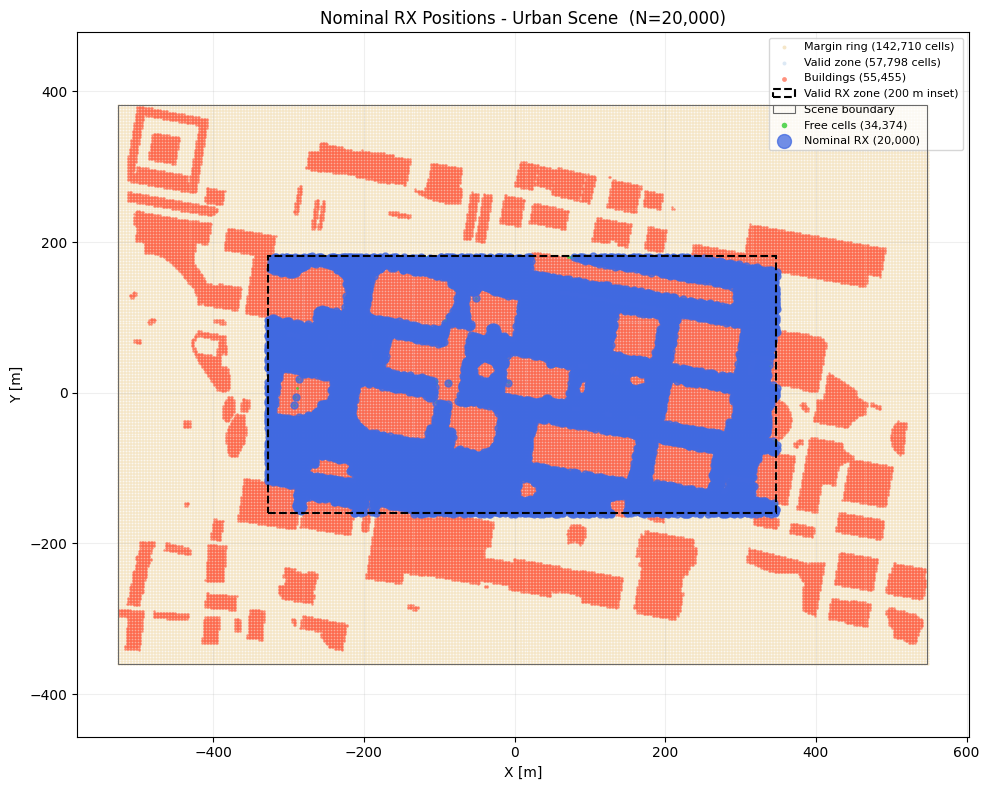

TX positions per elevation angle:
   20 deg  TX=(0.00 km, 0.94 km, 0.34 km)
   10 deg  TX=(0.00 km, 0.98 km, 0.17 km)


In [7]:
# Visualise receiver placement
fig = plot_rx_positions(
    nominal_rx_positions = nominal_rx_positions,
    tx_pos               = None,
    free_xy              = free_xy,
    title                = f"Nominal RX Positions - Urban Scene  (N={len(nominal_rx_positions):,})",
    grid_meta=grid_meta
)
fig.savefig(f"{OUTPUT_DIR}/rx_positions_overview.png", dpi=120, bbox_inches='tight')
plt.show()
print("TX positions per elevation angle:")
for _elev in ELEVATION_ANGLES:
    _tp, _angles = tx_position_from_elevation(_elev, SLANT_DIST_M, SCENE_CENTER, radius=0, azimuth_deg=TX_AZIMUTH_DEG)
    print(f"  {_elev:3.0f} deg  TX=({_tp[0]/1e3:.2f} km, {_tp[1]/1e3:.2f} km, {_tp[2]/1e3:.2f} km)")

## 6 - Launch Simulations (Multi-GPU)

Two elevation angles are dispatched simultaneously, one per GPU, by
launching `run_elevation_sim.py` as subprocesses with different
`CUDA_VISIBLE_DEVICES` values.

```
GPU 0: elev=10  ──────────────────────► done
GPU 1: elev=30  ──────────────────────► done
                                              | wait for both
GPU 0: elev=60  ──────────────────────► done
GPU 1: elev=80  ──────────────────────► done
```

Set `NUM_GPUS = 1` in Section 3 to run all angles sequentially on GPU 0.

> **Non-blocking mode:** set `BLOCK_UNTIL_DONE = False` to start the
> subprocesses and continue editing. Call `wait_for_procs(active_procs)` later.

In [ ]:
# ── Launch settings ─────────────────────────────────────────────────────────
# RESUME_FROM_CHECKPOINT: set this in the config cell above (cell 6).
# The launch cell reads it from the notebook namespace and passes it
# explicitly to each subprocess — no need to re-run the config cells.
BLOCK_UNTIL_DONE       = True  # False -> fire-and-forget
FORCE_FRESH_ANGLES     = []     # e.g. [10, 30] to force-restart specific angles
# RESUME_FROM_CHECKPOINT = False   # mirror of config-cell variable
os.makedirs(OUTPUT_DIR, exist_ok=True)
# Determine which angles still need to be run
angles_needed = []
for _angle in ELEVATION_ANGLES:
    _res_file = os.path.join(OUTPUT_DIR, f"results_elev{int(_angle):03d}deg.pkl")
    if os.path.exists(_res_file) and RESUME_FROM_CHECKPOINT and not (_angle in FORCE_FRESH_ANGLES):
        print(f"  elev={_angle} deg  -> already complete, skipping")
    else:
        angles_needed.append(_angle)
print(f"\nAngles to run: {angles_needed}")
def launch_angle(angle, gpu_id, resume, force_fresh=False):
    """Launch run_elevation_sim.py for one elevation angle.
    Args:
        resume      : value of RESUME_FROM_CHECKPOINT from the notebook
        force_fresh : if True, passes --no-resume regardless of `resume`
    The subprocess always receives an explicit --resume or --no-resume flag
    so the notebook variable is the authoritative source of truth.
    """
    _env = dict(os.environ)
    _env["CUDA_VISIBLE_DEVICES"] = str(gpu_id)
    _cmd = [
        sys.executable,
        os.path.join(SCRIPT_DIR, "run_elevation_sim.py"),
        "--elevation", str(angle),
        "--gpu_id",    str(gpu_id),
        "--config",    CONFIG_FILE,
        "--rx_file",   RX_POSITIONS_FILE,
        "--output",    OUTPUT_DIR,
    ]
    # Section 3.6: if a real/synthetic-orbit satellite source produced a
    # waypoints file, pass the matching waypoint index instead of relying
    # on --elevation alone (TX position AND velocity then come from the
    # real SGP4 pass sample -- see run_elevation_sim.py).
    _wp_file = globals().get("WAYPOINTS_FILE")
    if _wp_file:
        _wp_idx_map = globals().get("WAYPOINT_INDEX_BY_ANGLE", {})
        _wp_idx = _wp_idx_map.get(angle)
        if _wp_idx is None:
            raise KeyError(
                f"No waypoint index found for angle={angle} in "
                f"WAYPOINT_INDEX_BY_ANGLE -- did ELEVATION_ANGLES change after "
                f"Section 3.6 ran? Re-run Section 3.6 to regenerate it."
            )
        _cmd += ["--waypoints_file", _wp_file, "--waypoint_index", str(_wp_idx)]
    if force_fresh or not resume:
        _cmd.append("--no-resume")   # explicit fresh start
        if force_fresh:
            print(f"  [FORCE FRESH] elev={angle}° — checkpoint ignored (force_fresh)")
        else:
            print(f"  [FRESH START] elev={angle}° — checkpoint ignored (RESUME_FROM_CHECKPOINT=False)")
    else:
        _cmd.append("--resume")      # explicit resume
    _log = open(os.path.join(OUTPUT_DIR, f"log_elev{int(angle):03d}deg.txt"), "w")
    _p   = subprocess.Popen(_cmd, env=_env, stdout=_log, stderr=subprocess.STDOUT)
    print(f"  Launched PID {_p.pid}  elev={angle}°  GPU={gpu_id}  resume={resume and not force_fresh}")
    return _p
def wait_for_procs(procs, poll_interval=30):
    t0 = time.perf_counter()
    while True:
        still = [p for p in procs if p.poll() is None]
        if not still:
            break
        print(f"  [{time.strftime('%H:%M:%S')}]  {len(still)} still running  "
              f"({(time.perf_counter()-t0)/3600:.2f} h)")
        time.sleep(poll_interval)
    print(f"  All done.  Total: {(time.perf_counter()-t0)/3600:.2f} h")
# Dispatch
active_procs = []
if NUM_GPUS >= 2:
    _pairs = [angles_needed[i:i+2] for i in range(0, len(angles_needed), 2)]
    for _pair in _pairs:
        _pair_procs = []
        for _gpu_id, _angle in enumerate(_pair):
            _p = launch_angle(_angle, _gpu_id,
                              resume=RESUME_FROM_CHECKPOINT,
                              force_fresh=(_angle in FORCE_FRESH_ANGLES))
            _pair_procs.append(_p)
            active_procs.append(_p)
        if BLOCK_UNTIL_DONE:
            print(f"\nWaiting for pair {[a for a in _pair]}...")
            wait_for_procs(_pair_procs)
else:
    for _angle in angles_needed:
        _p = launch_angle(_angle, gpu_id=0,
                          resume=RESUME_FROM_CHECKPOINT,
                          force_fresh=(_angle in FORCE_FRESH_ANGLES))
        active_procs.append(_p)
        if BLOCK_UNTIL_DONE:
            wait_for_procs([_p])
if not BLOCK_UNTIL_DONE:
    print(f"\n{len(active_procs)} process(es) running in background.")
    print("Run: wait_for_procs(active_procs) to block until complete.")

In [ ]:
# Optional manual wait + status check
# wait_for_procs(active_procs)
simulation_status(OUTPUT_DIR, ELEVATION_ANGLES)

## 7 - Load Results

In [33]:
results_set = []

In [35]:
OUTPUT_DIR = "./plain_results_20km_medground"
all_results = load_all_results(OUTPUT_DIR, ELEVATION_ANGLES)
results_set.append(all_results)
if not all_results:
    print("No results found - run Section 6 first.")
else:
    print(f"Loaded results for {len(all_results)} elevation angle(s):")
    for _angle, _res in sorted(all_results.items()):
        _plos = np.mean(_res['los_probability']) * 100
        print(f"  {_angle:.0f} deg  N_RX={_res['n_rx_positions']:,}  P(LoS)={_plos:.1f}%")

[checkpoint] Loaded results  elev=80.0°  n_rx=10000
[checkpoint] Loaded results  elev=70.0°  n_rx=10000
[checkpoint] Loaded results  elev=60.0°  n_rx=10000
[checkpoint] Loaded results  elev=50.0°  n_rx=10000
[checkpoint] Loaded results  elev=40.0°  n_rx=10000
[checkpoint] Loaded results  elev=30.0°  n_rx=10000
[checkpoint] Loaded results  elev=20.0°  n_rx=10000
[checkpoint] Loaded results  elev=10.0°  n_rx=10000
Loaded results for 8 elevation angle(s):
  10 deg  N_RX=10,000  P(LoS)=100.0%
  20 deg  N_RX=10,000  P(LoS)=100.0%
  30 deg  N_RX=10,000  P(LoS)=100.0%
  40 deg  N_RX=10,000  P(LoS)=100.0%
  50 deg  N_RX=10,000  P(LoS)=100.0%
  60 deg  N_RX=10,000  P(LoS)=100.0%
  70 deg  N_RX=10,000  P(LoS)=100.0%
  80 deg  N_RX=10,000  P(LoS)=100.0%


## 7.5 - Quick Comparison

In [38]:
print(results_set[0].keys())

dict_keys([80.0, 70.0, 60.0, 50.0, 40.0, 30.0, 20.0, 10.0])


In [ ]:
angles  = sorted(all_results.keys())
labels  = [f"{int(a)}°" for a in angles]
colors  = plt.cm.plasma(np.linspace(0.1, 0.9, len(angles)))
K_mean  = []
for all_results in results_set:
    _K_mean = []
    for angle in angles:
        res = all_results[angle]
        P_los_arr = np.array(res["P_los"])
        P_nlos_arr = np.array(res["P_nlos"])
        mean_Plos  = float(np.mean(P_los_arr))
        mean_Pnlos = float(np.mean(P_nlos_arr))
        K_mean_dB   = 10.0 * np.log10(mean_Plos / (mean_Pnlos + 1e-30) + 1e-30)
        _K_mean.append(K_mean_dB)
    K_mean.append(_K_mean)
K_mean = np.array(K_mean, dtype=float)

ITU Concrete @ 2.4 GHz
  εᵣ  = 5.2400
  σ   = 0.09163116512581294 S/m
  εc  = 5.2400 - j0.6863
ITU Medium Dry Ground @ 2.4 GHz
  εᵣ  = 13.7426
  σ   = 0.1458184133409186 S/m
  εc  = 13.7426 - j1.0921

Brewster angle
  Analytical (lossless):      23.60°

Brewster angle
  Analytical (lossless):      15.10°


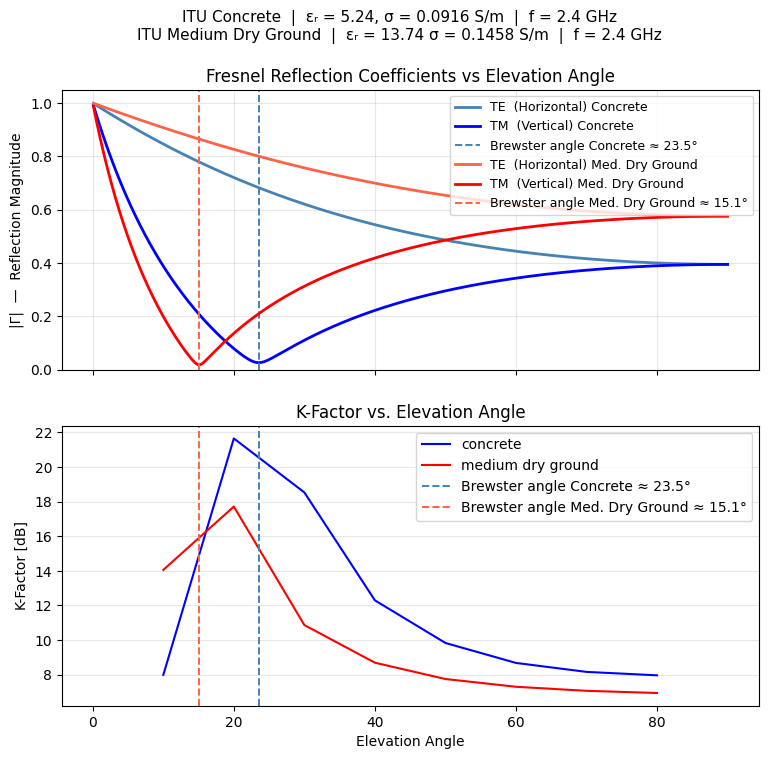

In [53]:
# ── ITU-R P.2040-1 concrete material properties ──────────────────────────────
# Model: εᵣ = a·f^b,  σ = c·f^d  (f in GHz)
def itu_concrete(freq_GHz, a,b,c,d):
    eps_r = a * freq_GHz**b      # b = 0 → frequency-independent ε
    sigma = c * freq_GHz**d
    return eps_r, sigma
freq_GHz = 2.4
eps_r_conc, sigma_conc = itu_concrete(freq_GHz, 5.24, 0.0, 0.0462, 0.7822)
eps_0 = 8.854187817e-12               # F/m
omega = 2 * np.pi * freq_GHz * 1e9   # rad/s
eps_conc = eps_r_conc - 1j * sigma_conc / (omega * eps_0)   # complex permittivity
print(f"ITU Concrete @ {freq_GHz} GHz")
print(f"  εᵣ  = {eps_r_conc:.4f}")
print(f"  σ   = {sigma_conc} S/m")
print(f"  εc  = {eps_conc.real:.4f} - j{abs(eps_conc.imag):.4f}")
eps_r_gr, sigma_gr = itu_concrete(freq_GHz, 15, -0.1, 0.035, 1.63)
eps_gr = eps_r_gr - 1j * sigma_gr / (omega * eps_0)   # complex permittivity
print(f"ITU Medium Dry Ground @ {freq_GHz} GHz")
print(f"  εᵣ  = {eps_r_gr:.4f}")
print(f"  σ   = {sigma_gr} S/m")
print(f"  εc  = {eps_gr.real:.4f} - j{abs(eps_gr.imag):.4f}")
# ── Elevation angle sweep ─────────────────────────────────────────────────────
# θ is the GRAZING / elevation angle measured from the surface (not the normal)
theta_deg = np.linspace(0.1, 90.0, 2000)
theta     = np.deg2rad(theta_deg)
# Fresnel coefficients in terms of grazing angle θ:
#
#          sin θ − √(εc − cos²θ)
# Γ_TE = ─────────────────────────       (horizontal / s-pol / HH)
#          sin θ + √(εc − cos²θ)
#
#       εc·sin θ − √(εc − cos²θ)
# Γ_TM = ─────────────────────────       (vertical   / p-pol / VV)
#       εc·sin θ + √(εc − cos²θ)
D = np.sqrt(eps_conc - np.cos(theta)**2)   # shared denominator term
Gamma_TE_conc = (np.sin(theta) - D)              / (np.sin(theta) + D)
Gamma_TM_conc = (eps_conc * np.sin(theta) - D)     / (eps_conc * np.sin(theta) + D)
mag_TE_conc,  mag_TM_conc  = np.abs(Gamma_TE_conc),    np.abs(Gamma_TM_conc)
phase_TE_conc, phase_TM_conc = np.angle(Gamma_TE_conc, deg=True), np.angle(Gamma_TM_conc, deg=True)
# ── Brewster angle ────────────────────────────────────────────────────────────
# For a lossy dielectric, Γ_TM never reaches exactly 0, so find the minimum
brewster_idx_conc   = np.argmin(mag_TM_conc)
brewster_angle_conc = theta_deg[brewster_idx_conc]
# Analytical lossless approximation: sin θ_B = 1/√(εᵣ+1)
brewster_lossless_conc = np.degrees(np.arcsin(1.0 / np.sqrt(eps_r_conc + 1)))
print(f"\nBrewster angle")
print(f"  Analytical (lossless):      {brewster_lossless_conc:.2f}°")
D_gr = np.sqrt(eps_gr- np.cos(theta)**2)   # shared denominator term
Gamma_TE_gr = (np.sin(theta) - D_gr)              / (np.sin(theta) + D_gr)
Gamma_TM_gr = (eps_gr * np.sin(theta) - D_gr)     / (eps_gr * np.sin(theta) + D_gr)
mag_TE_gr,  mag_TM_gr  = np.abs(Gamma_TE_gr),    np.abs(Gamma_TM_gr)
phase_TE_gr, phase_TM_gr = np.angle(Gamma_TE_gr, deg=True), np.angle(Gamma_TM_gr, deg=True)
# ── Brewster angle ────────────────────────────────────────────────────────────
# For a lossy dielectric, Γ_TM never reaches exactly 0, so find the minimum
brewster_idx_gr   = np.argmin(mag_TM_gr)
brewster_angle_gr = theta_deg[brewster_idx_gr]
# Analytical lossless approximation: sin θ_B = 1/√(εᵣ+1)
brewster_lossless_gr = np.degrees(np.arcsin(1.0 / np.sqrt(eps_r_gr + 1)))
print(f"\nBrewster angle")
print(f"  Analytical (lossless):      {brewster_lossless_gr:.2f}°")
# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)
fig.suptitle(
    f"ITU Concrete  |  εᵣ = {eps_r_conc:.2f}, "
    f"σ = {sigma_conc:.4f} S/m  |  f = {freq_GHz} GHz\n"
    f"ITU Medium Dry Ground  |  εᵣ = {eps_r_gr:.2f} "
    f"σ = {sigma_gr:.4f} S/m  |  f = {freq_GHz} GHz",
    fontsize=11
)
ax = axes[0]
ax.set_title(f"Fresnel Reflection Coefficients vs Elevation Angle")
ax.plot(theta_deg, mag_TE_conc, 'steelblue',  lw=2, label='TE  (Horizontal) Concrete')
ax.plot(theta_deg, mag_TM_conc, 'blue',     lw=2, label='TM  (Vertical) Concrete')
ax.axvline(brewster_angle_conc, color='steelblue', ls='--', lw=1.4,
           label=f'Brewster angle Concrete ≈ {brewster_angle_conc:.1f}°')
ax.plot(theta_deg, mag_TE_gr, 'tomato',  lw=2, label='TE  (Horizontal) Med. Dry Ground')
ax.plot(theta_deg, mag_TM_gr, 'red',     lw=2, label='TM  (Vertical) Med. Dry Ground')
ax.axvline(brewster_angle_gr, color='tomato', ls='--', lw=1.4,
           label=f'Brewster angle Med. Dry Ground ≈ {brewster_angle_gr:.1f}°')
ax.set_ylabel('|Γ|  —  Reflection Magnitude', fontsize=10)
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
ax = axes[1]
ax.set_title(
    "K-Factor vs. Elevation Angle"
)
ax.plot(angles, K_mean[0],color='blue', label="concrete")
ax.plot(angles, K_mean[1],color='red', label="medium dry ground")
ax.axvline(brewster_angle_conc, color='steelblue', ls='--', lw=1.4,
           label=f'Brewster angle Concrete ≈ {brewster_angle_conc:.1f}°')
ax.axvline(brewster_angle_gr, color='tomato', ls='--', lw=1.4,
           label=f'Brewster angle Med. Dry Ground ≈ {brewster_angle_gr:.1f}°')
# plt.xticks(x); 
ax.set_xlabel('Elevation Angle'); plt.ylabel('K-Factor [dB]')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

## 8 - Summary Statistics

In [6]:
for _angle in sorted(all_results.keys()):
    print_summary(all_results[_angle])
    # Per-mechanism power breakdown — LoS receivers only
    _res  = all_results[_angle]
    _n    = _res['n_rx_positions']
    _has_los  = np.array(_res['los_probability'], dtype=bool)
    _P_los_direct = np.array(_res.get('P_los', None) or ([0.0] * _n))
    _P_spec  = np.array(_res.get('P_specular',    [0.0] * _n))
    _P_diff  = np.array(_res.get('P_diffuse',     [0.0] * _n))
    _P_diffr = np.array(_res.get('P_diffraction', [0.0] * _n))
    _P_refr  = np.array(_res.get('P_refraction',  [0.0] * _n))
    _P_nlos  = np.array(_res.get('P_nlos',        [0.0] * _n))
    # Use directly stored P_los if available, otherwise reconstruct (backward compat)
    if np.any(_P_los_direct > 0):
        _P_los_arr = _P_los_direct
    else:
        _P_los_arr = np.array(_res['K_power_ratio']) * (_P_nlos + 1e-30)
    # Filter all power arrays to LoS receivers only
    _P_los_f  = _P_los_arr[_has_los]
    _P_spec_f = _P_spec[_has_los]
    _P_diff_f = _P_diff[_has_los]
    _P_diffr_f= _P_diffr[_has_los]
    _P_refr_f = _P_refr[_has_los]
    _P_nlos_f = _P_nlos[_has_los]
    _n_los    = int(np.sum(_has_los))
    # Ensemble K — LoS receivers only
    _K_ens    = float(np.mean(_P_los_f)) / (float(np.mean(_P_nlos_f)) + 1e-300)
    _K_ens_dB = 10.0 * np.log10(_K_ens + 1e-12)
    # Power breakdown — incoherent, LoS receivers only, ratio-of-means
    _P_total_inc = _P_los_f + _P_spec_f + _P_diff_f + _P_diffr_f + _P_refr_f + 1e-300
    _mean_tot    = float(np.mean(_P_total_inc))
    _frac_los    = float(np.mean(_P_los_f))   / _mean_tot * 100
    _frac_spec   = float(np.mean(_P_spec_f))  / _mean_tot * 100
    _frac_diff   = float(np.mean(_P_diff_f))  / _mean_tot * 100
    _frac_diffr  = float(np.mean(_P_diffr_f)) / _mean_tot * 100
    _frac_refr   = float(np.mean(_P_refr_f))  / _mean_tot * 100
    _total_frac  = _frac_los + _frac_spec + _frac_diff + _frac_diffr + _frac_refr
    print(f'  Ensemble K-Factor (LoS only, n={_n_los:,}): {_K_ens_dB:+.2f} dB  (linear {_K_ens:.3f})')
    print(f'  Power breakdown — LoS receivers only, ratio-of-means (sums to 100 %):')
    print(f'    P_los         : {_frac_los  :6.2f} %')
    print(f'    P_specular    : {_frac_spec :6.2f} %')
    print(f'    P_diffuse     : {_frac_diff :6.2f} %')
    print(f'    P_diffraction : {_frac_diffr:6.2f} %')
    print(f'    P_refraction  : {_frac_refr :6.2f} %')
    print(f'    ─────────────────────────────────')
    print(f'    Total         : {_total_frac:6.2f} %  (should be 100.00)')
    print()


══════════════════════════════════════════════════════════════════════
  CHANNEL STATISTICS  —  Elev = 10°  |  N_RX = 20,000
══════════════════════════════════════════════════════════════════════

  LoS Statistics:
  LoS positions                     3,820  (19.1 %)
  NLOS positions                    16,180  (80.9 %)

  Rician K-Factor  (LoS receivers only, n=3,820):
    K_ensemble [dB]                 +1.18 dB  (linear 1.3113)
    K per-RX [linear]               mean=2.1134  median=1.2483  std=7.2388  
    K per-RX [dB]                   mean=1.47  median=0.96  std=2.22  dB

  RMS Delay Spread  (LoS receivers, n=3,820):
    τ_rms LoS [ns]                  mean=64.6678  median=50.4268  std=48.0847  ns

  RMS Delay Spread  (NLOS receivers, n=16,180):
    τ_rms NLOS [ns]                 mean=260.4379  median=244.8459  std=141.0927  ns
══════════════════════════════════════════════════════════════════════
  Ensemble K-Factor (LoS only, n=3,820): +1.18 dB  (linear 1.311)
  Power breakdown

## 9 - Visualisation



## 9a.5 per elevation angle plots, polarization comparison


── VV 1km  (./urban_env_results_1km_V) ──
[checkpoint] Loaded results  elev=80.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=10.0°  n_rx=20000

── VV 20km  (./urban_env_results_20km_V) ──
[checkpoint] Loaded results  elev=80.0°  n_rx=20000
[checkpoint] Loaded results  elev=70.0°  n_rx=20000
[checkpoint] Loaded results  elev=60.0°  n_rx=20000
[checkpoint] Loaded results  elev=50.0°  n_rx=20000
[checkpoint] Loaded results  elev=40.0°  n_rx=20000
[checkpoint] Loaded results  elev=30.0°  n_rx=20000
[checkpoint] Loaded results  elev=20.0°  n_rx=20000
[checkpoint] Loaded results  elev=10.0°  n_rx=20000

── VV 400km  (./urban_env_results_400km_V) ──
[checkpoint] Loaded results  elev

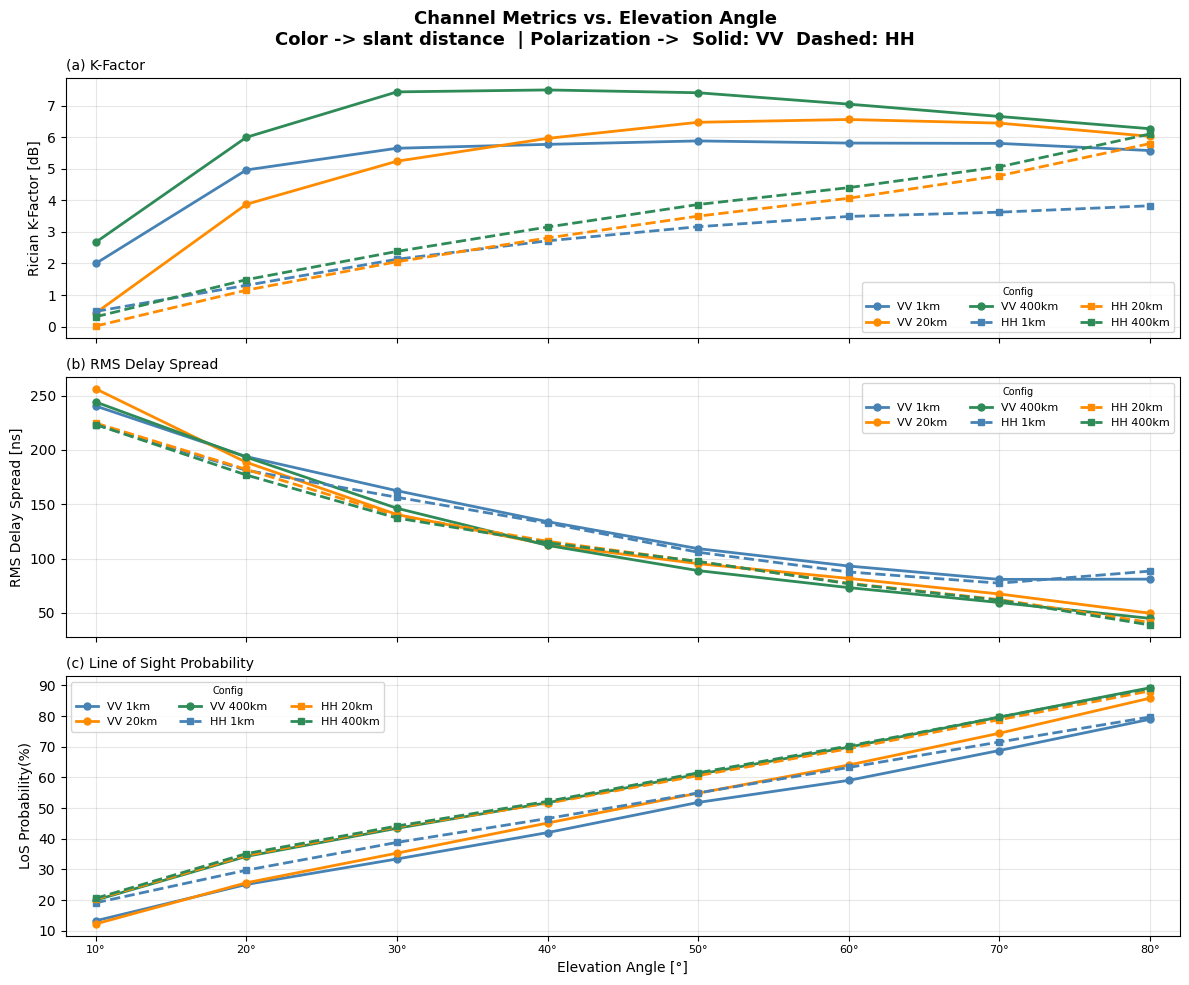

In [6]:
# ═══════════════════════════════════════════════════════════════════════════════
# Figure 6 — K-Factor & Delay Spread vs Elevation  (all 6 configs overlaid)
# ═══════════════════════════════════════════════════════════════════════════════
# ── 1.  Elevation angles that were simulated ────────────────────────────────
#   Edit this list to match exactly the angles you ran.
# ELEVATION_ANGLES = [10, 20, 30, 40, 50, 60, 70, 80]   # [°]
# ── 2.  Output directories — one per (polarisation × slant) config ──────────
#   Each directory must contain  results_elev{angle:03d}deg.pkl  files
#   produced by run_elevation_sim.py for that config.
OUTPUT_DIRS = {
    "VV 1km":   "./urban_env_results_1km_V",
    "VV 20km":  "./urban_env_results_20km_V",
    "VV 400km": "./urban_env_results_400km_V",
    "HH 1km":   "./urban_env_results_1km_H",
    "HH 20km":  "./urban_env_results_20km_H",
    "HH 400km": "./urban_env_results_400km_H"
}
# ── 3.  Load results for every config ───────────────────────────────────────
#   load_all_results returns  { elev_deg (float) : results_dict }
#   and prints a line per angle so you can see what loaded vs. was missing.
configs_results = {}
for label, out_dir in OUTPUT_DIRS.items():
    print(f"\n── {label}  ({out_dir}) ──")
    angle_results = load_all_results(out_dir, ELEVATION_ANGLES)
    if not angle_results:
        print(f"   WARNING: no results found — config will be skipped in plot")
    configs_results[label] = angle_results
# ── 4.  Plot ────────────────────────────────────────────────────────────────
fig = plot_metrics_vs_elevation_multi_config(
    configs_results,
    marker_every = 1,
    figsize      = (12, 10),
)
# ── 5.  Save ────────────────────────────────────────────────────────────────
os.makedirs("./figures", exist_ok=True)
fig.savefig("./figures/fig6_metrics_vs_elevation_multi_config.png",
            dpi=150, bbox_inches="tight")
print("\nSaved → ./figures/fig6_metrics_vs_elevation_multi_config.png")
plt.show()

### 9a - Spatial Heat-Maps (per elevation angle)

K-Factor and RMS Delay Spread overlaid on the scene footprint.

In [ ]:
os.makedirs(OUTPUT_DIR, exist_ok=True)
_cfg_lbl = (
    f"max_depth={MAX_DEPTH}  "
    f"{'LoS ' if LOS else ''}"
    f"{'Spec ' if SPECULAR_REFLECTION else ''}"
    f"{'DiffRefl ' if DIFFUSE_REFLECTION else ''}"
    f"{'Diffr' if DIFFRACTION else ''}"
)
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_spatial_stats(
        nominal_rx_positions = _res['nominal_rx_positions'],
        K_power_ratio        = _res['K_power_ratio'],
        tau_rms_mean_s       = _res['tau_rms_mean_s'],
        los_probability      = _res['los_probability'],
        elevation_deg        = _angle,
        frequency            = FREQUENCY,
        slant_dist_m         = SLANT_DIST_M,
        cfg_label            = _cfg_lbl,
    )
    _fname = os.path.join(OUTPUT_DIR, f'spatial_stats_elev{int(_angle):03d}deg.png')
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Saved -> {_fname}')


### 9b - LoS / NLOS Maps

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_los_map(
        nominal_rx_positions = _res["nominal_rx_positions"],
        los_probability      = _res["los_probability"],
        elevation_deg        = _angle,
    )
    _fname = os.path.join(OUTPUT_DIR, f"los_map_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {_fname}")

### 9c - CDFs (per elevation angle)

In [ ]:
for _angle in sorted(all_results.keys()):
    _res = all_results[_angle]
    fig  = plot_cdfs(
        K_power_ratio   = _res["K_power_ratio"],
        tau_rms_mean_s  = _res["tau_rms_mean_s"],
        los_probability = _res["los_probability"],
        elevation_deg   = _angle,
    )
    _fname = os.path.join(OUTPUT_DIR, f"cdfs_elev{int(_angle):03d}deg.png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {_fname}")

### 9d - Cross-Angle Comparison

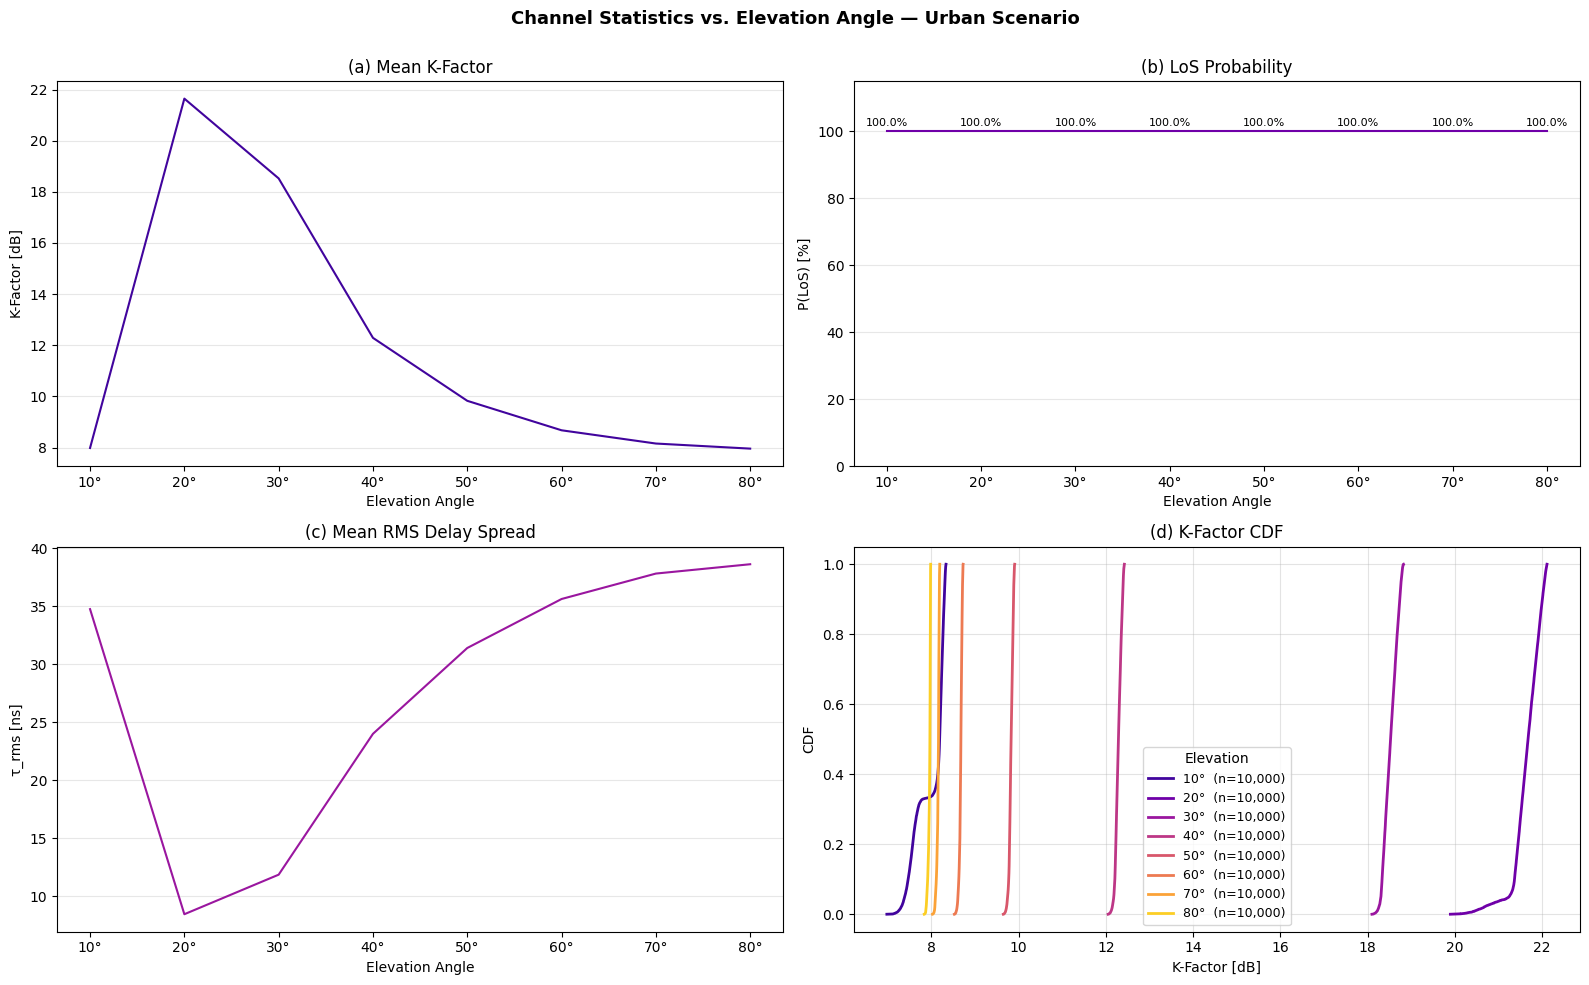

Saved -> ./plain_results_20km_concrete/angle_comparison.png


In [25]:
if len(all_results) >= 2:
    fig    = plot_angle_comparison(all_results)
    _fname = os.path.join(OUTPUT_DIR, "angle_comparison.png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Saved -> {_fname}")
else:
    print("Need at least 2 completed elevation angles for comparison plot.")

## 10 - CIR Viewer

- Set `CIR_RX_IDX` to `'best_los'`, `'worst_los'`, or an integer index.
- Set `CIR_ANGLE` to the elevation angle you want to inspect.

In [24]:
ang = sorted(all_results.keys())[2]
print(all_results[ang]["raw_results"][0].keys())

dict_keys(['rx_nominal', 'taus', 'amps', 'inter_d0', 'P_los', 'P_scat', 'P_specular', 'P_diffuse', 'P_diffraction', 'P_refraction', 'P_nlos', 'tau_rms_s', 'h_env', 'has_los'])


NLOS RX indices (full array) : [   2    3    4 ... 9997 9998 9999]
Valid NLOS RX options for CIR inspection : [799, 1199, 1599, 3199, 3599, 5199, 5599, 6399, 6799, 7199, 7999, 9999]
799


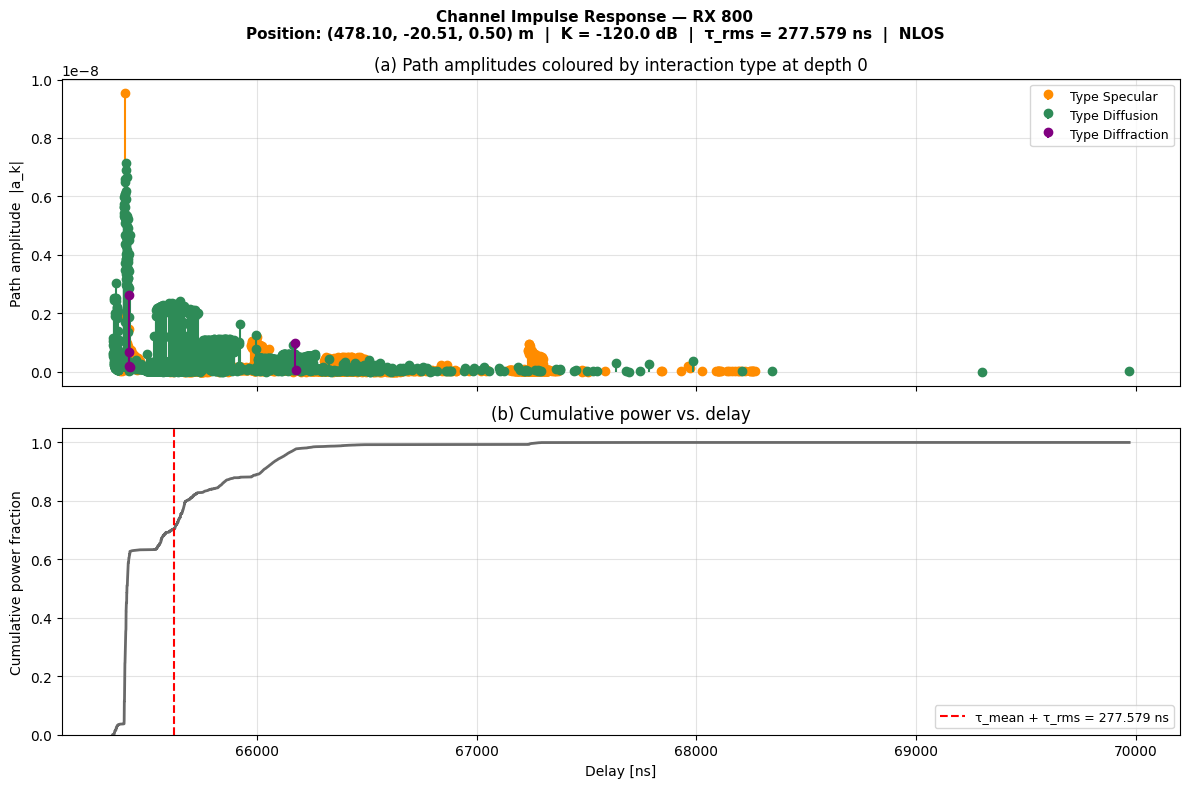

Saved -> ./urban_env_results_depth/cir_elev030deg_rx800.png
Total paths: 7056  |  LoS: 0  |  Scatter/diff: 7056


In [45]:
CIR_ANGLE = sorted(all_results.keys())[1]
# ── Identify NLOS receivers ───────────────────────────────────────────────────
_res            = all_results[CIR_ANGLE]
_raw    = _res["raw_results"]
has_los         = np.asarray(_res["los_probability"], dtype=bool)
nlos_idx        = np.where(~has_los)[0]          # indices into the full rx array
valid_idx_options = [i for i in range(40000) if (i + 1) % RAW_SAVE_INTERVAL == 0]
valid_nlos_idx_options =[i for i in nlos_idx if (i + 1) % RAW_SAVE_INTERVAL == 0]
print(f"NLOS RX indices (full array) : {nlos_idx}")
print(f"Valid NLOS RX options for CIR inspection : {valid_nlos_idx_options}")
# ── Pick a receiver ───────────────────────────────────────────────────────────
# Integer → index into the NLOS subset  (0 … len(nlos_idx)-1)
# 'best_los'  → LoS raw result with highest  P_los / P_scat
# 'worst_los' → LoS raw result with lowest   P_los / P_scat
CIR_RX_IDX = valid_nlos_idx_options[0]  # <-- edit this
# CIR_RX_IDX = 'best_los'  # <-- edit this
# ── Shared arrays ─────────────────────────────────────────────────────────────
_K_pr   = np.array(_res["K_power_ratio"])
_tau_ns = np.array(_res["tau_rms_mean_s"]) * 1e9
_K_dB   = 10 * np.log10(_K_pr + 1e-12)
_raw    = _res["raw_results"]
_rx_pos = np.array(_res["nominal_rx_positions"])
# print(len(_raw))
if len(_raw) == 0:
    print("No raw_results available - decrease RAW_SAVE_INTERVAL and re-run.")
else:
    if CIR_RX_IDX == 'best_los':
        _cands = [r for r in _raw if r['has_los']] or _raw
        _r_inspect = max(_cands, key=lambda r: r['P_los'] / (r['P_scat'] + 1e-30))
    elif CIR_RX_IDX == 'worst_los':
        _cands = [r for r in _raw if r['has_los']] or _raw
        _r_inspect = min(_cands, key=lambda r: r['P_los'] / (r['P_scat'] + 1e-30))
    else:
        _r_inspect = _raw[np.where(valid_idx_options == CIR_RX_IDX)[0][0]]
        # _r_inspect = _raw[int(CIR_RX_IDX)]
    _nom    = np.array(_r_inspect["rx_nominal"])
    _dists  = np.linalg.norm(_rx_pos - _nom, axis=1)
    _rx_idx = int(np.argmin(_dists))
    print(_rx_idx)
    fig = plot_cir(
        raw_result = _r_inspect,
        rx_idx     = _rx_idx,
        K_dB       = _K_dB[_rx_idx],
        tau_rms_ns = _tau_ns[_rx_idx],
    )
    _fname = os.path.join(OUTPUT_DIR, f"cir_elev{int(CIR_ANGLE):03d}deg_rx" + str(_rx_idx+1) + ".png")
    fig.savefig(_fname, dpi=150, bbox_inches='tight')
    plt.show()
    print("Saved -> " + _fname)
    _id0       = np.array(_r_inspect['inter_d0'])
    _n_los     = int(np.sum(_id0 == 0))
    _n_scatter = len(_id0) - _n_los
    print("Total paths: " + str(len(_r_inspect['taus'])) +
          "  |  LoS: " + str(_n_los) +
          "  |  Scatter/diff: " + str(_n_scatter))

## 12 - Optional: Scene Preview (last solved geometry)

In [ ]:
VIS_ANGLE  = sorted(all_results.keys())[0]
VIS_RX_IDX = 0
_res_vis = all_results[VIS_ANGLE]
_tx_pos  = _res_vis["tx_pos"]
_rx_vis  = _res_vis["nominal_rx_positions"][VIS_RX_IDX]
print(f"Building scene for  elev={VIS_ANGLE:.0f} deg  RX #{VIS_RX_IDX+1} ...")
_scene_vis, _ = build_scene_batch([_rx_vis], _tx_pos, cfg)
_solver_vis = PathSolver()
_seed_vis   = drjit.cuda.ad.UInt(0)
_paths_vis = _solver_vis(
    scene                 = _scene_vis,
    max_depth             = MAX_DEPTH,
    los                   = LOS,
    specular_reflection   = SPECULAR_REFLECTION,
    diffuse_reflection    = DIFFUSE_REFLECTION,
    refraction            = REFRACTION,
    diffraction           = DIFFRACTION,
    edge_diffraction      = EDGE_DIFFRACTION,
    synthetic_array       = False,
    max_num_paths_per_src = 200,
    samples_per_src       = 50_000,
    seed                  = _seed_vis,
)
_amp_v, _tau_v = _paths_vis.cir(normalize_delays=False, out_type="numpy")
_valid = np.abs(_amp_v[0, 0, 0, 0, :, 0]) > 0
print(f"Paths found: {int(np.sum(_valid))}")
print(f"  Delays [ns]: {_tau_v[0,0,0,0,_valid][:10]*1e9}")